# Review Opinion Miner — Organized Code Notebook

This copy keeps the original code and its order, but adds a separate heading and a short purpose note before each code cell.

## How to use this notebook
- Each **Part** is a separate code cell. Run cells from top to bottom when they belong to the workflow you are using.
- This notebook contains **multiple alternative dataset-loading methods** (Hugging Face Hub, `datasets`, Parquet, and direct URL download). These are alternatives, not steps that all need to be run. Choose one successful loading route that creates `df`.
- Some later cells reuse variables created earlier, such as `df`, `clean_df`, `X_train`, `models`, and `preprocessor`.
- I have added labels and explanations only; the existing executable code has not been rewritten. Some older cells may repeat tasks or reflect earlier experiments.
- Google Colab's `/content/` storage is temporary. Save the notebook and important output files to Google Drive.


## A. Project setup and initial data exploration


### Part 01 — Project setup and environment check

Imports the main libraries and prints the Python and package versions.


In [ ]:

# Review Opinion Miner
# Data Lead: Awais Khan

import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Project: Review Opinion Miner")
print("Role: Data Lead")
print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("\nEnvironment is ready!")


Project: Review Opinion Miner
Role: Data Lead
Python version: 3.13.16
Pandas version: 2.2.3
NumPy version: 2.1.3

Environment is ready!


### Part 02 — Install Hugging Face Hub

Installs a compatible Hugging Face Hub package. Usually run only if the import in a later cell fails.


In [ ]:

%pip install "huggingface_hub>=0.25.0,<2.0"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 20.7 MB/s eta 0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 2.2.0
    Uninstalling huggingface_hub-2.2.0:
      Successfully uninstalled huggingface_hub-2.2.0


### Part 04 — Verify installed libraries

Checks versions of Hugging Face Hub, pandas, and NumPy.


In [ ]:

import huggingface_hub
import pandas as pd
import numpy as np

print("Hugging Face Hub:", huggingface_hub.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


Hugging Face Hub: 2.2.0
Pandas: 2.2.3
NumPy: 2.1.3


### Part 05 — Find dataset files on Hugging Face

Lists matching All_Beauty files in the dataset repository; it does not download review data.


In [ ]:

from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_files(
    repo_id="McAuley-Lab/Amazon-Reviews-2023",
    repo_type="dataset"
)

matches = [
    path for path in files
    if "All_Beauty" in path
    and (
        "review_categories" in path
        or "meta_categories" in path
    )
]

print("Matching files:", len(matches))

for path in matches:
    print(path)


Matching files: 2
raw/meta_categories/meta_All_Beauty.jsonl
raw/review_categories/All_Beauty.jsonl


### Part 06 — Import JSON and compression helpers

Imports libraries used by JSONL/compressed dataset loading.


In [ ]:

import pandas as pd
import gzip
import json
from huggingface_hub import hf_hub_download

print("Libraries imported successfully!")


Libraries imported successfully!


### Part 07 — Download the review file from Hugging Face

Attempts to download the All_Beauty JSONL file through Hugging Face Hub.


In [ ]:

from huggingface_hub import hf_hub_download

review_file = hf_hub_download(
    repo_id="McAuley-Lab/Amazon-Reviews-2023",
    repo_type="dataset",
    filename="raw/review_categories/All_Beauty.jsonl"
)

print("Dataset downloaded successfully!")
print("File location:", review_file)


raw/review_categories/All_Beauty.jsonl: reconstructing file:   0%|          |  0.00B /  327MB            

raw/review_categories/All_Beauty.jsonl: downloading bytes:           |  0.00B            

Dataset downloaded successfully!
File location: /root/.cache/huggingface/hub/datasets--McAuley-Lab--Amazon-Reviews-2023/snapshots/2b6d039ed471f2ba5fd2acb718bf33b0a7e5598e/raw/review_categories/All_Beauty.jsonl


### Part 08 — Load the first 1,000 reviews

Reads up to 1,000 JSONL records into the original DataFrame named df.


In [ ]:

reviews = []

with open(review_file, "r", encoding="utf-8") as file:
    for i, line in enumerate(file):
        reviews.append(json.loads(line))
        if i == 999:
            break

df = pd.DataFrame(reviews)

print("Sample loaded successfully!")
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
print("\nColumn names:")
print(df.columns.tolist())

df.head()


Sample loaded successfully!
Number of rows: 1000
Number of columns: 10

Column names:
['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5.0,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588687728923,0,True
1,4.0,Works great but smells a little weird.,"This product does what I need it to do, I just...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588615855070,1,True
2,5.0,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,1589665266052,2,True
3,1.0,Synthetic feeling,Felt synthetic,[],B09JS339BZ,B09JS339BZ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,1643393630220,0,True
4,5.0,A+,Love it,[],B08BZ63GMJ,B08BZ63GMJ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,1609322563534,0,True


### Part 09 — Inspect dataset structure

Shows shape, data types, sample titles, and review text.


In [ ]:

print("Dataset shape:", df.shape)

print("\nColumn data types:")
print(df.dtypes)

print("\nFirst 5 review titles:")
print(df["title"].head())

print("\nFirst 5 review texts:")
print(df["text"].head())


Dataset shape: (1000, 10)

Column data types:
rating               float64
title                 object
text                  object
images                object
asin                  object
parent_asin           object
user_id               object
timestamp              int64
helpful_vote           int64
verified_purchase       bool
dtype: object

First 5 review titles:
0    Such a lovely scent but not overpowering.
1       Works great but smells a little weird.
2                                         Yes!
3                            Synthetic feeling
4                                           A+
Name: title, dtype: object

First 5 review texts:
0    This spray is really nice. It smells really go...
1    This product does what I need it to do, I just...
2                            Smells good, feels great!
3                                       Felt synthetic
4                                              Love it
Name: text, dtype: object


### Part 10 — Check missing values

Counts missing values and calculates their percentages by column.


In [ ]:

missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df) * 100).round(2)
})

print(missing_report)


                   Missing Values  Missing Percentage
rating                          0                 0.0
title                           0                 0.0
text                            0                 0.0
images                          0                 0.0
asin                            0                 0.0
parent_asin                     0                 0.0
user_id                         0                 0.0
timestamp                       0                 0.0
helpful_vote                    0                 0.0
verified_purchase               0                 0.0


### Part 11 — Check duplicate records

Checks exact duplicates and duplicate review identifiers.


In [ ]:

# Check exact duplicate rows, including columns that contain lists
df_for_duplicates = df.copy()

for col in df_for_duplicates.columns:
    df_for_duplicates[col] = df_for_duplicates[col].map(
        lambda x: json.dumps(x, sort_keys=True)
        if isinstance(x, (list, dict))
        else x
    )

print("Exact duplicate rows:", df_for_duplicates.duplicated().sum())

print(
    "Duplicate review identifiers (user_id + asin + timestamp):",
    df.duplicated(subset=["user_id", "asin", "timestamp"]).sum()
)


Exact duplicate rows: 0
Duplicate review identifiers (user_id + asin + timestamp): 0


### Part 12 — Explore star-rating distribution

Counts ratings and plots their distribution.


Rating counts:
rating
1.0     63
2.0     63
3.0    111
4.0    189
5.0    574
Name: count, dtype: int64


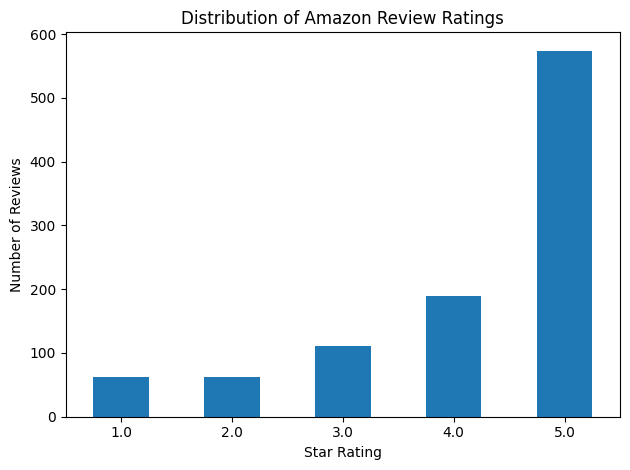

In [ ]:

rating_counts = df["rating"].value_counts().sort_index()

print("Rating counts:")
print(rating_counts)

rating_counts.plot(
    kind="bar",
    xlabel="Star Rating",
    ylabel="Number of Reviews",
    title="Distribution of Amazon Review Ratings",
    rot=0
)

plt.tight_layout()
plt.show()


### Part 13 — Summarize helpful votes

Shows helpful-vote statistics and counts reviews with zero or nonzero votes.


In [ ]:

print("Helpful vote summary:")
print(df["helpful_vote"].describe())

print("\nReviews with at least one helpful vote:")
print((df["helpful_vote"] > 0).sum())

print("\nReviews with zero helpful votes:")
print((df["helpful_vote"] == 0).sum())


Helpful vote summary:
count    1000.000000
mean        1.310000
std        13.955739
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max       430.000000
Name: helpful_vote, dtype: float64

Reviews with at least one helpful vote:
294

Reviews with zero helpful votes:
706


## B. Cleaning and feature engineering


### Part 14 — Clean the dataset

Creates clean_df and applies the cleaning rules written in this cell.


In [ ]:

# Keep the original dataset unchanged
clean_df = df.copy()

# Remove rows without review text or rating
clean_df = clean_df.dropna(subset=["text", "rating"]).copy()

# Remove reviews with empty text
clean_df["text"] = clean_df["text"].astype(str).str.strip()
clean_df = clean_df[clean_df["text"] != ""].copy()

# Ensure ratings and helpful votes are numeric
clean_df["rating"] = pd.to_numeric(
    clean_df["rating"], errors="coerce"
)

clean_df["helpful_vote"] = pd.to_numeric(
    clean_df["helpful_vote"], errors="coerce"
)

# Remove rows with invalid ratings
clean_df = clean_df[
    clean_df["rating"].between(1, 5)
].copy()

print("Original rows:", len(df))
print("Rows after cleaning:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))
print("\nMissing values in key columns:")
print(clean_df[["text", "rating", "helpful_vote"]].isnull().sum())


Original rows: 1000
Rows after cleaning: 1000
Rows removed: 0

Missing values in key columns:
text            0
rating          0
helpful_vote    0
dtype: int64


### Part 16 — Create sentiment labels

Maps ratings to Negative, Neutral, or Positive.


In [ ]:

def label_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

clean_df["sentiment"] = clean_df["rating"].apply(label_sentiment)

print("Sentiment column created successfully!")
print(clean_df["sentiment"].value_counts())


Sentiment column created successfully!
sentiment
Positive    763
Negative    126
Neutral     111
Name: count, dtype: int64


### Part 17 — Convert timestamps to review dates

Creates readable UTC dates from millisecond timestamps.


In [ ]:

clean_df["review_date"] = pd.to_datetime(
    clean_df["timestamp"],
    unit="ms",
    errors="coerce",
    utc=True
)

print("Earliest review:", clean_df["review_date"].min())
print("Latest review:", clean_df["review_date"].max())


Earliest review: 2005-08-09 12:12:58+00:00
Latest review: 2023-03-11 21:45:21.367000+00:00


### Part 18 — Validate engineered columns

Displays the cleaned data shape, sentiment counts, date range, and sample rows.


In [ ]:

print("Dataset shape:", clean_df.shape)

print("\nSentiment labels:")
print(clean_df["sentiment"].value_counts())

print("\nReview date range:")
print("Earliest:", clean_df["review_date"].min())
print("Latest:", clean_df["review_date"].max())

print("\nSample of cleaned data:")
display(
    clean_df[
        ["rating", "sentiment", "helpful_vote", "review_date", "text"]
    ].head()
)


Dataset shape: (1000, 12)

Sentiment labels:
sentiment
Positive    763
Negative    126
Neutral     111
Name: count, dtype: int64

Review date range:
Earliest: 2005-08-09 12:12:58+00:00
Latest: 2023-03-11 21:45:21.367000+00:00

Sample of cleaned data:


,rating,sentiment,helpful_vote,review_date,text
0,5.0,Positive,0,2020-05-05 14:08:48.923000+00:00,This spray is really nice. It smells really go...
1,4.0,Positive,1,2020-05-04 18:10:55.070000+00:00,"This product does what I need it to do, I just..."
2,5.0,Positive,2,2020-05-16 21:41:06.052000+00:00,"Smells good, feels great!"
3,1.0,Negative,0,2022-01-28 18:13:50.220000+00:00,Felt synthetic
4,5.0,Positive,0,2020-12-30 10:02:43.534000+00:00,Love it


### Part 19 — Calculate review length

Adds a review-length feature measured in words in this cell.


In [ ]:

clean_df["review_length"] = clean_df["text"].str.split().str.len()

print("Review length statistics:")
print(clean_df["review_length"].describe())


Review length statistics:
count    1000.000000
mean       90.448000
std       124.269369
min         1.000000
25%        18.000000
50%        59.000000
75%       108.000000
max      1511.000000
Name: review_length, dtype: float64


### Part 20 — Analyze helpful votes by sentiment

Summarizes helpful-vote counts and statistics for each sentiment group.


In [ ]:

helpfulness_by_sentiment = clean_df.groupby("sentiment")["helpful_vote"].agg(
    ["count", "mean", "median", "max"]
)

print(helpfulness_by_sentiment)


           count      mean  median  max
sentiment                              
Negative     126  0.873016     0.0   24
Neutral      111  0.459459     0.0    7
Positive     763  1.505898     0.0  430


## C. Exploratory Data Analysis and target definition


### Part 21 — Plot review length against helpful votes

Creates a scatter plot to inspect the relationship between review length and helpful votes.


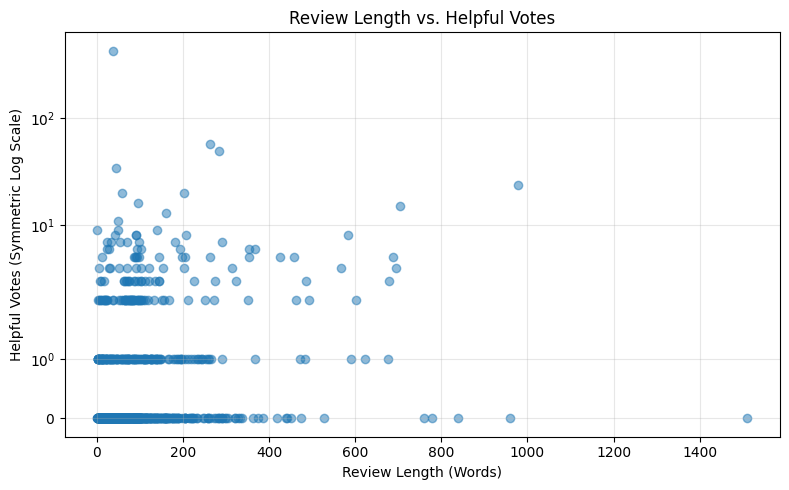

In [ ]:

plt.figure(figsize=(8, 5))

plt.scatter(
    clean_df["review_length"],
    clean_df["helpful_vote"],
    alpha=0.5
)

plt.yscale("symlog")
plt.xlabel("Review Length (Words)")
plt.ylabel("Helpful Votes (Symmetric Log Scale)")
plt.title("Review Length vs. Helpful Votes")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Part 22 — Create the helpful-vote prediction target

Adds received_helpful_vote: 1 for at least one helpful vote, otherwise 0.


In [ ]:

clean_df["received_helpful_vote"] = (
    clean_df["helpful_vote"] > 0
).astype(int)

print("Target distribution:")
print(
    clean_df["received_helpful_vote"]
    .value_counts()
    .rename(index={0: "Zero votes", 1: "At least one vote"})
)

print("\nTarget percentages:")
print(
    (clean_df["received_helpful_vote"].value_counts(normalize=True) * 100)
    .round(2)
    .rename(index={0: "Zero votes", 1: "At least one vote"})
)


Target distribution:
received_helpful_vote
Zero votes           706
At least one vote    294
Name: count, dtype: int64

Target percentages:
received_helpful_vote
Zero votes           70.6
At least one vote    29.4
Name: proportion, dtype: float64


### Part 23 — Inspect columns and feature missingness

Lists available columns and checks missing values in candidate model features.


In [ ]:

print("Available columns:")
print(clean_df.columns.tolist())

print("\nMissing values in potential features:")
print(
    clean_df[
        ["rating", "text", "review_length", "verified_purchase", "review_date"]
    ].isnull().sum()
)


Available columns:
['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase', 'sentiment', 'review_date', 'review_length', 'received_helpful_vote']

Missing values in potential features:
rating               0
text                 0
review_length        0
verified_purchase    0
review_date          0
dtype: int64


### Part 24 — Summarize target class distribution

Displays counts and percentages for the binary helpful-vote target.


In [ ]:

print(
    clean_df["received_helpful_vote"]
    .value_counts()
    .rename(index={0: "Zero votes", 1: "At least one vote"})
)

print("\nPercentages:")
print(
    (clean_df["received_helpful_vote"].value_counts(normalize=True) * 100)
    .round(2)
)


received_helpful_vote
Zero votes           706
At least one vote    294
Name: count, dtype: int64

Percentages:
received_helpful_vote
0    70.6
1    29.4
Name: proportion, dtype: float64


## D. Initial machine-learning experiments


### Part 25 — Import machine-learning tools

Imports the preprocessing, modeling, splitting, and evaluation functions used below.


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    average_precision_score
)

print("Machine-learning libraries imported successfully!")


Machine-learning libraries imported successfully!


### Part 26 — Create training and test sets

Selects model features and target, then creates a stratified train/test split.


In [ ]:

features = clean_df[
    ["text", "rating", "review_length", "verified_purchase"]
].copy()

target = clean_df["received_helpful_vote"]

X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.20,
    random_state=42,
    stratify=target
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training rows: 800
Testing rows: 200

Training target distribution:
received_helpful_vote
0    565
1    235
Name: count, dtype: int64

Testing target distribution:
received_helpful_vote
0    141
1     59
Name: count, dtype: int64


### Part 27 — Build and train the TF-IDF model pipeline

Preprocesses review text and metadata, then fits Logistic Regression.


In [ ]:

preprocessor = ColumnTransformer(
    transformers=[
        (
            "text",
            TfidfVectorizer(max_features=3000, ngram_range=(1, 2)),
            "text"
        ),
        (
            "other",
            StandardScaler(with_mean=False),
            ["rating", "review_length", "verified_purchase"]
        )
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]
)

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


### Part 28 — Evaluate the trained model

Calculates predictions, balanced accuracy, classification report, confusion matrix, and average precision.


In [ ]:

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Balanced accuracy:")
print(round(balanced_accuracy_score(y_test, y_pred), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Zero votes", "At least one vote"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print(
    "\nAverage precision (PR-AUC-style metric):",
    round(average_precision_score(y_test, y_prob), 4)
)


Balanced accuracy:
0.6025

Classification report:
                   precision    recall  f1-score   support

       Zero votes       0.77      0.73      0.75       141
At least one vote       0.42      0.47      0.45        59

         accuracy                           0.66       200
        macro avg       0.60      0.60      0.60       200
     weighted avg       0.67      0.66      0.66       200

Confusion matrix:
[[103  38]
 [ 31  28]]

Average precision (PR-AUC-style metric): 0.4977


### Part 29 — Compare classification algorithms

Trains and evaluates several candidate classifiers using the setup in this cell.


In [ ]:

from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, average_precision_score
from sklearn.dummy import DummyClassifier

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=10,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        max_depth=15,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Average Precision": average_precision_score(
            y_test, probabilities
        )
    })

# Majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

results.append({
    "Model": "Majority Baseline",
    "Macro F1": f1_score(
        y_test, baseline_predictions, average="macro"
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test, baseline_predictions
    ),
    "Average Precision": average_precision_score(
        y_test, baseline_predictions
    )
})

results_df = pd.DataFrame(results).sort_values(
    by="Macro F1", ascending=False
)

print(results_df.round(4).to_string(index=False))


              Model  Macro F1  Balanced Accuracy  Average Precision
      Random Forest    0.6094             0.6058             0.5697
Logistic Regression    0.5985             0.6025             0.4977
      Decision Tree    0.5889             0.5982             0.4340
  Majority Baseline    0.4135             0.5000             0.2950


### Part 30 — Create a time-based train/test split

Uses older reviews for training and newer reviews for testing.


In [ ]:

# Sort reviews from oldest to newest
time_df = clean_df.sort_values("review_date").reset_index(drop=True)

# Use the oldest 80% for training and newest 20% for testing
split_index = int(len(time_df) * 0.80)

train_df = time_df.iloc[:split_index].copy()
test_df = time_df.iloc[split_index:].copy()

feature_columns = [
    "text",
    "rating",
    "review_length",
    "verified_purchase"
]

X_train_time = train_df[feature_columns].copy()
y_train_time = train_df["received_helpful_vote"]

X_test_time = test_df[feature_columns].copy()
y_test_time = test_df["received_helpful_vote"]

print("Training reviews:", len(train_df))
print("Testing reviews:", len(test_df))

print("\nTraining date range:")
print(train_df["review_date"].min(), "to", train_df["review_date"].max())

print("\nTesting date range:")
print(test_df["review_date"].min(), "to", test_df["review_date"].max())

print("\nTraining target distribution:")
print(y_train_time.value_counts())

print("\nTesting target distribution:")
print(y_test_time.value_counts())


Training reviews: 800
Testing reviews: 200

Training date range:
2005-08-09 12:12:58+00:00 to 2021-07-19 02:40:38.992000+00:00

Testing date range:
2021-07-19 14:44:39.323000+00:00 to 2023-03-11 21:45:21.367000+00:00

Training target distribution:
received_helpful_vote
0    553
1    247
Name: count, dtype: int64

Testing target distribution:
received_helpful_vote
0    153
1     47
Name: count, dtype: int64


### Part 31 — Evaluate models on the time-based split

Trains candidate models and records metrics on the time-based test set.


In [ ]:

time_results = []

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(classifier))
    ])

    pipeline.fit(X_train_time, y_train_time)

    predictions = pipeline.predict(X_test_time)
    probabilities = pipeline.predict_proba(X_test_time)[:, 1]

    time_results.append({
        "Model": name,
        "Macro F1": f1_score(
            y_test_time, predictions, average="macro"
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test_time, predictions
        ),
        "Average Precision": average_precision_score(
            y_test_time, probabilities
        )
    })

time_results_df = pd.DataFrame(time_results).sort_values(
    "Macro F1", ascending=False
)

print(time_results_df.round(4).to_string(index=False))


              Model  Macro F1  Balanced Accuracy  Average Precision
      Random Forest    0.5787             0.5737             0.3699
Logistic Regression    0.5733             0.5771             0.3697
      Decision Tree    0.5097             0.5117             0.2233


### Part 32 — Compare random and time-based evaluations

Combines metrics from the random split and time-based split for comparison.


In [ ]:

random_results_df = results_df[
    ["Model", "Macro F1", "Balanced Accuracy", "Average Precision"]
].copy()

random_results_df["Evaluation"] = "Random split"

time_comparison = time_results_df[
    ["Model", "Macro F1", "Balanced Accuracy", "Average Precision"]
].copy()

time_comparison["Evaluation"] = "Time-based split"

final_comparison = pd.concat(
    [random_results_df, time_comparison],
    ignore_index=True
)

final_comparison = final_comparison[
    ["Evaluation", "Model", "Macro F1",
     "Balanced Accuracy", "Average Precision"]
]

display(final_comparison.round(4))


,Evaluation,Model,Macro F1,Balanced Accuracy,Average Precision
0,Random split,Random Forest,0.6094,0.6058,0.5697
1,Random split,Logistic Regression,0.5985,0.6025,0.4977
2,Random split,Decision Tree,0.5889,0.5982,0.4340
3,Random split,Majority Baseline,0.4135,0.5000,0.2950
4,Time-based split,Random Forest,0.5787,0.5737,0.3699
5,Time-based split,Logistic Regression,0.5733,0.5771,0.3697
6,Time-based split,Decision Tree,0.5097,0.5117,0.2233


### Part 33 — Save model comparison results

Exports the comparison table to a CSV file.


In [ ]:

final_comparison.to_csv(
    "helpfulness_model_comparison.csv",
    index=False
)

print("Comparison saved successfully!")


Comparison saved successfully!


## E. Project status and alternative data-loading attempts


### Part 34 — Check current project progress

Checks whether key project variables exist and displays their shapes and columns.


In [ ]:

# Step 1: Check our current project progress

print("REVIEW OPINION MINER - PROJECT STATUS")
print("=" * 45)

variables_to_check = ["df", "clean_df", "monthly_report"]

for name in variables_to_check:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: EXISTS")
        print(f"Type: {type(obj).__name__}")

        if hasattr(obj, "shape"):
            print(f"Shape: {obj.shape}")

        if hasattr(obj, "columns"):
            print("Columns:")
            print(list(obj.columns))
    else:
        print(f"\n{name}: NOT FOUND")

if "clean_df" in globals():
    print("\nFirst 5 cleaned records:")
    display(clean_df.head())

elif "df" in globals():
    print("\nFirst 5 original records:")
    display(df.head())


REVIEW OPINION MINER - PROJECT STATUS

df: NOT FOUND

clean_df: NOT FOUND

monthly_report: NOT FOUND


### Part 42 — Alternative loader D: Download and read official JSONL

Downloads the official compressed JSONL source and reads records into df; inspect the rest of the cell for its row limit.


In [ ]:

import requests
import gzip
import json
import pandas as pd
import os

url = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/All_Beauty.jsonl.gz"
file_path = "/content/All_Beauty.jsonl.gz"

print("Downloading official review dataset...")

with requests.get(url, stream=True, timeout=180) as response:
    response.raise_for_status()
    with open(file_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

print("Download complete!")
print("File size:", round(os.path.getsize(file_path) / (1024 * 1024), 2), "MB")

records = []

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    for line in f:
        records.append(json.loads(line))
        if len(records) == 1000:
            break

df = pd.DataFrame(records)

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Download complete!
File size: 90.07 MB

Dataset loaded successfully!
Shape: (1000, 10)
Columns: ['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5.0,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588687728923,0,True
1,4.0,Works great but smells a little weird.,"This product does what I need it to do, I just...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588615855070,1,True
2,5.0,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,1589665266052,2,True
3,1.0,Synthetic feeling,Felt synthetic,[],B09JS339BZ,B09JS339BZ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,1643393630220,0,True
4,5.0,A+,Love it,[],B08BZ63GMJ,B08BZ63GMJ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,1609322563534,0,True


## F. Current data preparation and EDA workflow


### Part 43 — Clean data and engineer features

Creates clean_df, applies the cleaning steps in this cell, and prepares the dataset for analysis.


In [ ]:

import pandas as pd
import numpy as np

# Keep the original dataset unchanged
clean_df = df.copy()

print("Missing values before cleaning:")
print(clean_df.isnull().sum())

# Check duplicates using columns with scalar values
duplicate_columns = [
    "rating",
    "title",
    "text",
    "asin",
    "parent_asin",
    "user_id",
    "timestamp",
    "helpful_vote",
    "verified_purchase"
]

duplicates = clean_df.duplicated(
    subset=duplicate_columns
).sum()

clean_df = clean_df.drop_duplicates(
    subset=duplicate_columns
).copy()

# Handle missing text fields
clean_df["title"] = clean_df["title"].fillna("").astype(str)
clean_df["text"] = clean_df["text"].fillna("").astype(str)

# Remove empty review text
clean_df = clean_df[
    clean_df["text"].str.strip().ne("")
].copy()

# Keep valid ratings from 1 to 5
clean_df = clean_df[
    clean_df["rating"].between(1, 5)
].copy()

print("\nDATA QUALITY SUMMARY")
print("-" * 35)
print("Original rows:", len(df))
print("Duplicates found:", duplicates)
print("Rows after cleaning:", len(clean_df))
print("\nRemaining missing values:")
print(clean_df.isnull().sum())

display(clean_df.head())


Missing values before cleaning:
rating               0
title                0
text                 0
images               0
asin                 0
parent_asin          0
user_id              0
timestamp            0
helpful_vote         0
verified_purchase    0
dtype: int64

DATA QUALITY SUMMARY
-----------------------------------
Original rows: 1000
Duplicates found: 0
Rows after cleaning: 1000

Remaining missing values:
rating               0
title                0
text                 0
images               0
asin                 0
parent_asin          0
user_id              0
timestamp            0
helpful_vote         0
verified_purchase    0
dtype: int64


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5.0,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588687728923,0,True
1,4.0,Works great but smells a little weird.,"This product does what I need it to do, I just...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588615855070,1,True
2,5.0,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,1589665266052,2,True
3,1.0,Synthetic feeling,Felt synthetic,[],B09JS339BZ,B09JS339BZ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,1643393630220,0,True
4,5.0,A+,Love it,[],B08BZ63GMJ,B08BZ63GMJ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,1609322563534,0,True


### Part 44 — Add date, length, sentiment, and target features

Creates derived columns for dates, review length, sentiment, and helpful-vote prediction.


In [ ]:

import pandas as pd
import numpy as np

# Convert timestamps from milliseconds to readable dates
clean_df["review_date"] = pd.to_datetime(
    clean_df["timestamp"],
    unit="ms",
    errors="coerce",
    utc=True
)

# Calculate review text length
clean_df["review_length"] = clean_df["text"].str.len()

# Assign sentiment based on star ratings
clean_df["sentiment"] = np.select(
    [
        clean_df["rating"] <= 2,
        clean_df["rating"] == 3,
        clean_df["rating"] >= 4
    ],
    [
        "Negative",
        "Neutral",
        "Positive"
    ],
    default="Unknown"
)

# Create binary target for helpful-vote prediction
clean_df["received_helpful_vote"] = (
    clean_df["helpful_vote"].fillna(0) > 0
).astype(int)

print("Feature engineering completed!")
print("Dataset shape:", clean_df.shape)

display(
    clean_df[
        [
            "rating",
            "sentiment",
            "review_date",
            "review_length",
            "helpful_vote",
            "received_helpful_vote"
        ]
    ].head(10)
)


Feature engineering completed!
Dataset shape: (1000, 14)


,rating,sentiment,review_date,review_length,helpful_vote,received_helpful_vote
0,5.0,Positive,2020-05-05 14:08:48.923000+00:00,300,0,0
1,4.0,Positive,2020-05-04 18:10:55.070000+00:00,235,1,1
2,5.0,Positive,2020-05-16 21:41:06.052000+00:00,25,2,1
3,1.0,Negative,2022-01-28 18:13:50.220000+00:00,14,0,0
4,5.0,Positive,2020-12-30 10:02:43.534000+00:00,7,0,0
5,4.0,Positive,2020-08-27 22:30:08.138000+00:00,125,0,0
6,5.0,Positive,2021-09-17 13:31:59.443000+00:00,144,0,0
7,3.0,Neutral,2021-10-15 05:20:59.292000+00:00,171,0,0
8,5.0,Positive,2021-07-27 13:04:04.559000+00:00,388,0,0
9,5.0,Positive,2021-07-18 13:21:51.145000+00:00,457,0,0


### Part 45 — Print EDA summary statistics

Summarizes sentiment, helpful-vote distribution, ratings, and review length.


In [ ]:

print("=" * 45)
print("REVIEW OPINION MINER — EDA SUMMARY")
print("=" * 45)

print("\n1. SENTIMENT DISTRIBUTION")
print(clean_df["sentiment"].value_counts())

print("\n2. HELPFUL-VOTE DISTRIBUTION")
target_counts = clean_df["received_helpful_vote"].value_counts().reindex(
    [0, 1], fill_value=0
)
print(target_counts.rename({
    0: "No helpful votes",
    1: "At least one helpful vote"
}))

print("\n3. HELPFUL-VOTE PERCENTAGES")
print((target_counts / len(clean_df) * 100).round(2))

print("\n4. STAR RATING SUMMARY")
print(clean_df["rating"].describe())

print("\n5. REVIEW LENGTH SUMMARY")
print(clean_df["review_length"].describe())

print("\n6. DATE RANGE")
print("Earliest:", clean_df["review_date"].min())
print("Latest:", clean_df["review_date"].max())

print("\n7. AVERAGE REVIEW LENGTH BY SENTIMENT")
print(clean_df.groupby("sentiment")["review_length"].mean().round(2))


REVIEW OPINION MINER — EDA SUMMARY

1. SENTIMENT DISTRIBUTION
sentiment
Positive    763
Negative    126
Neutral     111
Name: count, dtype: int64

2. HELPFUL-VOTE DISTRIBUTION
received_helpful_vote
No helpful votes             706
At least one helpful vote    294
Name: count, dtype: int64

3. HELPFUL-VOTE PERCENTAGES
received_helpful_vote
0    70.6
1    29.4
Name: count, dtype: float64

4. STAR RATING SUMMARY
count    1000.000000
mean        4.148000
std         1.218023
min         1.000000
25%         4.000000
50%         5.000000
75%         5.000000
max         5.000000
Name: rating, dtype: float64

5. REVIEW LENGTH SUMMARY
count     1000.00000
mean       495.89000
std        724.29236
min          4.00000
25%         96.00000
50%        302.50000
75%        584.00000
max      10205.00000
Name: review_length, dtype: float64

6. DATE RANGE
Earliest: 2005-08-09 12:12:58+00:00
Latest: 2023-03-11 21:45:21.367000+00:00

7. AVERAGE REVIEW LENGTH BY SENTIMENT
sentiment
Negative    352.25


### Part 46 — Plot EDA charts

Creates a multi-panel figure showing review and target distributions.


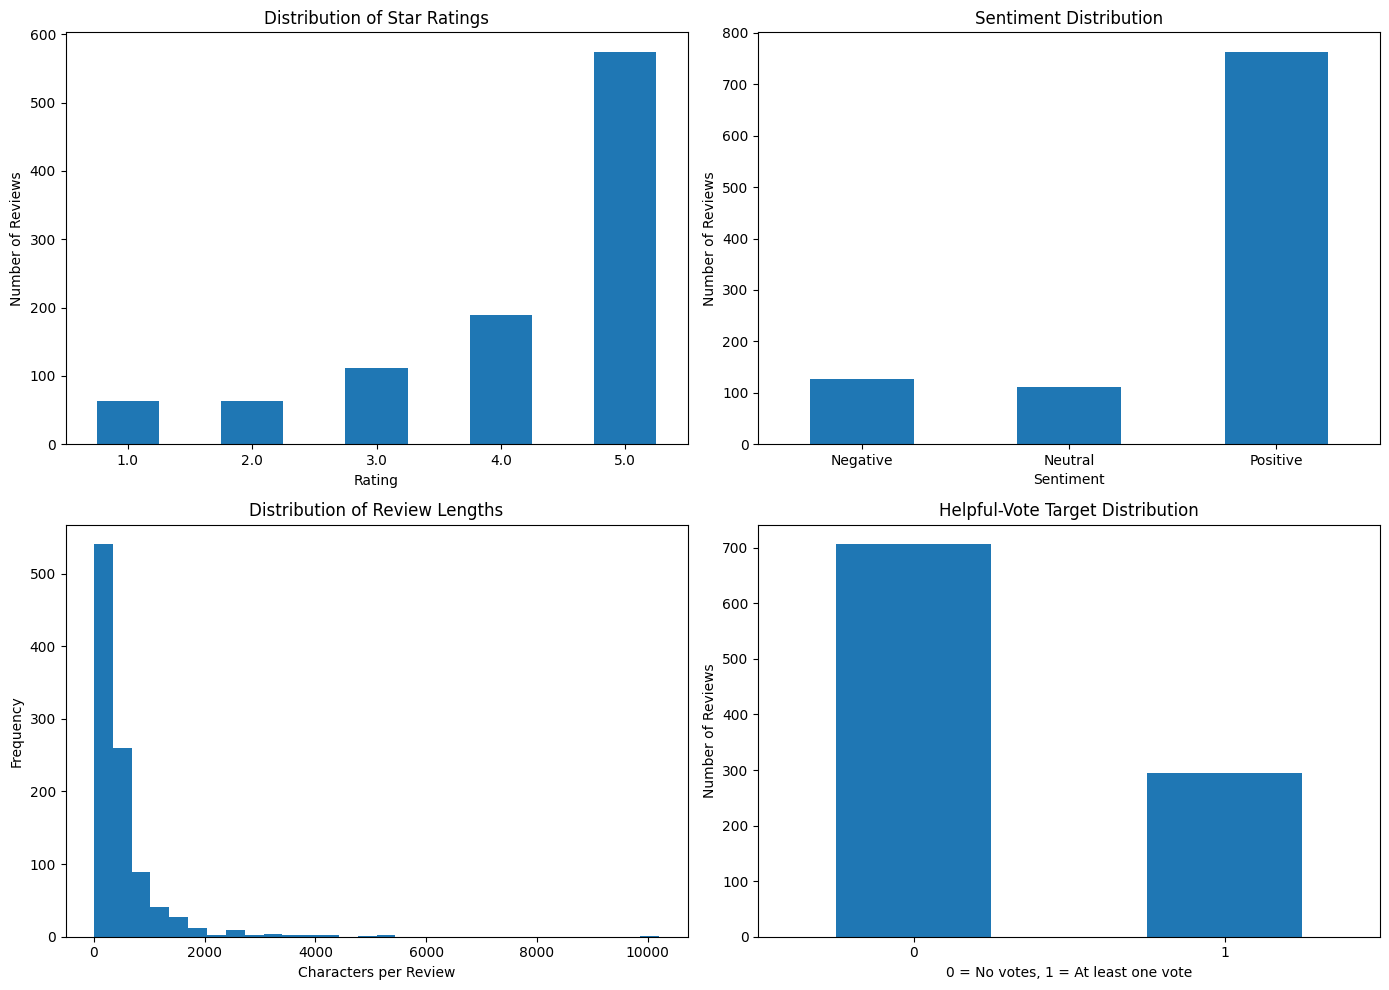

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: Star ratings
clean_df["rating"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of Star Ratings")
axes[0, 0].set_xlabel("Rating")
axes[0, 0].set_ylabel("Number of Reviews")
axes[0, 0].tick_params(axis="x", rotation=0)

# Chart 2: Sentiment
clean_df["sentiment"].value_counts().reindex(
    ["Negative", "Neutral", "Positive"], fill_value=0
).plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Sentiment Distribution")
axes[0, 1].set_xlabel("Sentiment")
axes[0, 1].set_ylabel("Number of Reviews")
axes[0, 1].tick_params(axis="x", rotation=0)

# Chart 3: Review lengths
axes[1, 0].hist(clean_df["review_length"], bins=30)
axes[1, 0].set_title("Distribution of Review Lengths")
axes[1, 0].set_xlabel("Characters per Review")
axes[1, 0].set_ylabel("Frequency")

# Chart 4: Helpful-vote target
target_counts = clean_df["received_helpful_vote"].value_counts().reindex(
    [0, 1], fill_value=0
)
target_counts.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Helpful-Vote Target Distribution")
axes[1, 1].set_xlabel("0 = No votes, 1 = At least one vote")
axes[1, 1].set_ylabel("Number of Reviews")
axes[1, 1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


### Part 47 — Check target and feature distributions

Prints target counts, target percentages, review-length statistics, and ratings.


In [ ]:

import pandas as pd
import numpy as np

target = "received_helpful_vote"

print("TARGET DISTRIBUTION")
print(clean_df[target].value_counts().sort_index())

print("\nTARGET PERCENTAGES")
print((clean_df[target].value_counts(normalize=True) * 100).round(2))

print("\nTARGET CLASS COUNTS")
print("No helpful votes:", (clean_df[target] == 0).sum())
print("At least one helpful vote:", (clean_df[target] == 1).sum())

print("\nREVIEW LENGTH SUMMARY")
print(clean_df["review_length"].describe())

print("\nRATING DISTRIBUTION")
print(clean_df["rating"].value_counts().sort_index())


TARGET DISTRIBUTION
received_helpful_vote
0    706
1    294
Name: count, dtype: int64

TARGET PERCENTAGES
received_helpful_vote
0    70.6
1    29.4
Name: proportion, dtype: float64

TARGET CLASS COUNTS
No helpful votes: 706
At least one helpful vote: 294

REVIEW LENGTH SUMMARY
count     1000.00000
mean       495.89000
std        724.29236
min          4.00000
25%         96.00000
50%        302.50000
75%        584.00000
max      10205.00000
Name: review_length, dtype: float64

RATING DISTRIBUTION
rating
1.0     63
2.0     63
3.0    111
4.0    189
5.0    574
Name: count, dtype: int64


## G. Initial model training and comparison


### Part 48 — Train the numeric baseline model

Splits the data and trains Logistic Regression using rating and review length.


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)

# Input features available from review content
X = clean_df[["rating", "review_length"]].copy()
y = clean_df["received_helpful_vote"].copy()

# Split before fitting the model
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Scale features and train logistic regression
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("BASELINE MODEL: LOGISTIC REGRESSION")
print("=" * 40)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print("Macro-F1:", round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, zero_division=0))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))


BASELINE MODEL: LOGISTIC REGRESSION
Training records: 700
Testing records: 300
Balanced accuracy: 0.6197
Macro-F1: 0.6193

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.78      0.77      0.78       212
           1       0.46      0.47      0.46        88

    accuracy                           0.68       300
   macro avg       0.62      0.62      0.62       300
weighted avg       0.68      0.68      0.68       300

CONFUSION MATRIX
[[164  48]
 [ 47  41]]


### Part 49 — Save EDA charts

Creates and saves EDA charts in the project output folder.


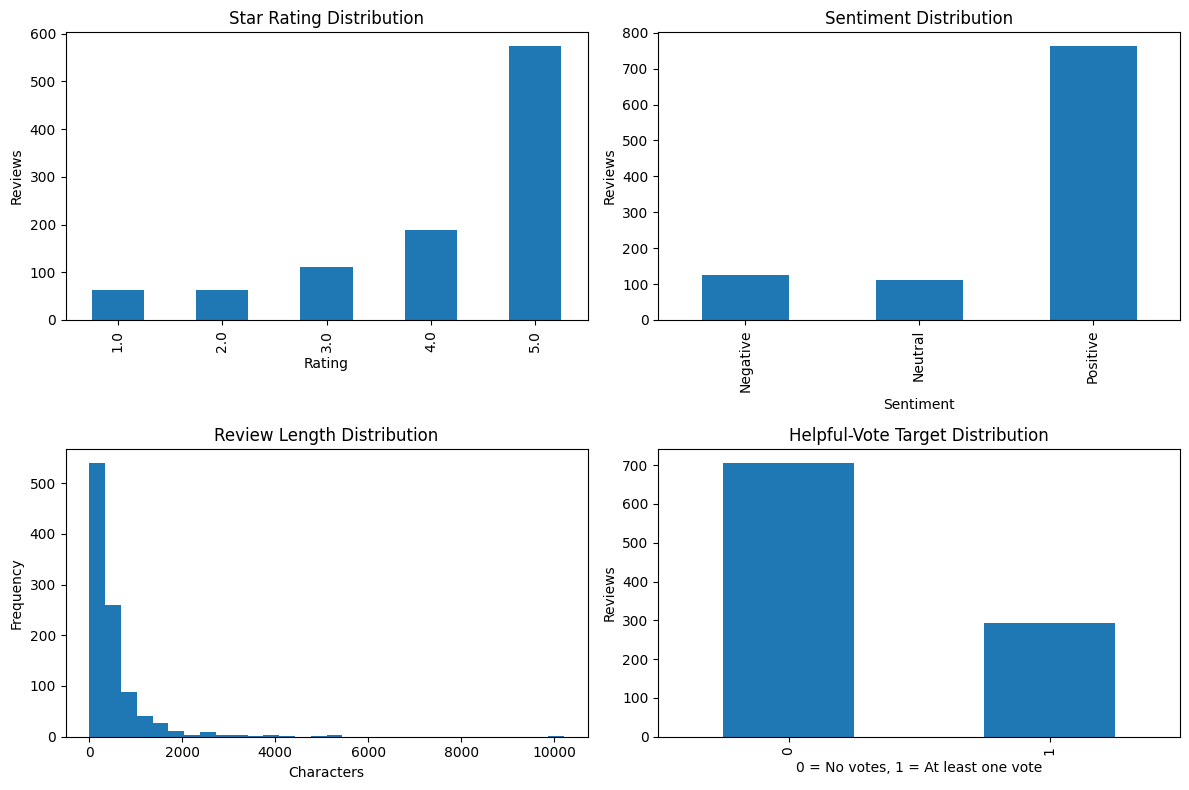

Charts saved to: /content/review_opinion_miner_outputs/eda_charts.png


In [ ]:

import matplotlib.pyplot as plt
import os

os.makedirs("/content/review_opinion_miner_outputs", exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

clean_df["rating"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0, 0]
)
axes[0, 0].set_title("Star Rating Distribution")
axes[0, 0].set_xlabel("Rating")
axes[0, 0].set_ylabel("Reviews")

clean_df["sentiment"].value_counts().reindex(
    ["Negative", "Neutral", "Positive"], fill_value=0
).plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Sentiment Distribution")
axes[0, 1].set_xlabel("Sentiment")
axes[0, 1].set_ylabel("Reviews")

axes[1, 0].hist(clean_df["review_length"], bins=30)
axes[1, 0].set_title("Review Length Distribution")
axes[1, 0].set_xlabel("Characters")
axes[1, 0].set_ylabel("Frequency")

clean_df["received_helpful_vote"].value_counts().reindex(
    [0, 1], fill_value=0
).plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Helpful-Vote Target Distribution")
axes[1, 1].set_xlabel("0 = No votes, 1 = At least one vote")
axes[1, 1].set_ylabel("Reviews")

plt.tight_layout()

chart_path = "/content/review_opinion_miner_outputs/eda_charts.png"
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

print("Charts saved to:", chart_path)


### Part 50 — Generate baseline evaluation report

Produces classification metrics and saves baseline results to CSV.


In [ ]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)
import pandas as pd
import os

# Reuse the trained model if it already exists;
# otherwise, train the baseline model.
if "model" not in globals() or "X_test" not in globals():
    from sklearn.model_selection import train_test_split
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression

    X = clean_df[["rating", "review_length"]].copy()
    y = clean_df["received_helpful_vote"].copy()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=42, stratify=y
    )

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        )
    )
    model.fit(X_train, y_train)

y_pred = model.predict(X_test)

results = {
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Macro F1": f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )
}

print("BASELINE MODEL RESULTS")
for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

report = pd.DataFrame(
    classification_report(
        y_test, y_pred, output_dict=True, zero_division=0
    )
).transpose()

print("\nCLASSIFICATION REPORT")
display(report.round(4))

print("\nCONFUSION MATRIX")
display(pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

output_dir = "/content/review_opinion_miner_outputs"
os.makedirs(output_dir, exist_ok=True)

report.to_csv(f"{output_dir}/baseline_classification_report.csv")
pd.DataFrame([results]).to_csv(
    f"{output_dir}/baseline_metrics.csv", index=False
)

print("\nBaseline results saved successfully.")


BASELINE MODEL RESULTS
Balanced Accuracy: 0.6197
Macro F1: 0.6193

CLASSIFICATION REPORT


,precision,recall,f1-score,support
0,0.7773,0.7736,0.7754,212.0000
1,0.4607,0.4659,0.4633,88.0000
accuracy,0.6833,0.6833,0.6833,0.6833
macro avg,0.6190,0.6197,0.6193,300.0000
weighted avg,0.6844,0.6833,0.6839,300.0000



CONFUSION MATRIX


,Predicted 0,Predicted 1
Actual 0,164,48
Actual 1,47,41



Baseline results saved successfully.


### Part 51 — Train and evaluate the TF-IDF text model

Uses review title/body text with TF-IDF and Logistic Regression.


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import os

# Combine review title and review body
text_data = (
    clean_df["title"].fillna("").astype(str)
    + " "
    + clean_df["text"].fillna("").astype(str)
).str.strip()

# Reuse the exact same train/test split as the baseline
X_text_train = text_data.loc[X_train.index]
X_text_test = text_data.loc[X_test.index]

y_text_train = clean_df.loc[X_train.index, "received_helpful_vote"]
y_text_test = clean_df.loc[X_test.index, "received_helpful_vote"]

# Build the text classification pipeline
text_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_features=20000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Train the model
text_model.fit(X_text_train, y_text_train)

# Predict on the same test set as the baseline
text_pred = text_model.predict(X_text_test)

# Evaluate performance
text_balanced_accuracy = balanced_accuracy_score(
    y_text_test, text_pred
)
text_macro_f1 = f1_score(
    y_text_test, text_pred,
    average="macro", zero_division=0
)

print("TF-IDF + LOGISTIC REGRESSION")
print("=" * 40)
print("Balanced accuracy:", round(text_balanced_accuracy, 4))
print("Macro-F1:", round(text_macro_f1, 4))

print("\nClassification report:")
print(classification_report(
    y_text_test, text_pred, zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_text_test, text_pred))


TF-IDF + LOGISTIC REGRESSION
Balanced accuracy: 0.5918
Macro-F1: 0.5946

Classification report:
              precision    recall  f1-score   support

           0       0.76      0.80      0.78       212
           1       0.44      0.39      0.41        88

    accuracy                           0.68       300
   macro avg       0.60      0.59      0.59       300
weighted avg       0.67      0.68      0.67       300

Confusion matrix:
[[169  43]
 [ 54  34]]


### Part 52 — Compare baseline and text models

Builds a comparison table and saves model metrics.


In [ ]:

comparison = pd.DataFrame([
    {
        "Model": "Baseline: Rating + Review Length",
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Macro-F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    },
    {
        "Model": "TF-IDF + Logistic Regression",
        "Balanced Accuracy": text_balanced_accuracy,
        "Macro-F1": text_macro_f1
    }
])

comparison = comparison.round(4)

print("MODEL COMPARISON")
display(comparison)

output_dir = "/content/review_opinion_miner_outputs"
os.makedirs(output_dir, exist_ok=True)

comparison.to_csv(
    f"{output_dir}/model_comparison.csv",
    index=False
)

print("Comparison saved successfully.")


MODEL COMPARISON


,Model,Balanced Accuracy,Macro-F1
0,Baseline: Rating + Review Length,0.6197,0.6193
1,TF-IDF + Logistic Regression,0.5918,0.5946


Comparison saved successfully.


### Part 53 — Train the combined text-and-metadata model

Uses text, rating, review length, and verified-purchase status.


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score
import pandas as pd
import os

# Prepare features that could be available when a review is submitted
combined_df = clean_df.copy()

combined_df["review_text"] = (
    combined_df["title"].fillna("").astype(str)
    + " "
    + combined_df["text"].fillna("").astype(str)
).str.strip()

combined_df["verified_purchase"] = (
    combined_df["verified_purchase"].fillna(False).astype(str)
)

feature_columns = [
    "review_text",
    "rating",
    "review_length",
    "verified_purchase"
]

X_combined = combined_df[feature_columns]
y_combined = combined_df["received_helpful_vote"]

# Reuse the existing train/test indices for a fair comparison
X_combined_train = X_combined.loc[X_train.index]
X_combined_test = X_combined.loc[X_test.index]
y_combined_train = y_combined.loc[X_train.index]
y_combined_test = y_combined.loc[X_test.index]

# Process text and numerical/categorical features separately
preprocessor = ColumnTransformer([
    (
        "text",
        TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 2),
            min_df=2,
            max_features=20000,
            sublinear_tf=True
        ),
        "review_text"
    ),
    (
        "numeric",
        StandardScaler(),
        ["rating", "review_length"]
    ),
    (
        "verified",
        OneHotEncoder(handle_unknown="ignore"),
        ["verified_purchase"]
    )
])

combined_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

combined_model.fit(X_combined_train, y_combined_train)
combined_pred = combined_model.predict(X_combined_test)

combined_bal_acc = balanced_accuracy_score(
    y_combined_test, combined_pred
)
combined_macro_f1 = f1_score(
    y_combined_test,
    combined_pred,
    average="macro",
    zero_division=0
)

print("COMBINED-FEATURE MODEL")
print("=" * 40)
print("Balanced accuracy:", round(combined_bal_acc, 4))
print("Macro-F1:", round(combined_macro_f1, 4))


COMBINED-FEATURE MODEL
Balanced accuracy: 0.6031
Macro-F1: 0.6059


### Part 54 — Compare three initial models

Displays and saves the baseline, text-only, and combined model comparison.


In [ ]:

comparison = pd.DataFrame([
    {
        "Model": "Baseline: Rating + Review Length",
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Macro-F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    },
    {
        "Model": "TF-IDF + Logistic Regression",
        "Balanced Accuracy": text_balanced_accuracy,
        "Macro-F1": text_macro_f1
    },
    {
        "Model": "Combined: Text + Metadata",
        "Balanced Accuracy": combined_bal_acc,
        "Macro-F1": combined_macro_f1
    }
]).round(4)

display(comparison)

output_dir = "/content/review_opinion_miner_outputs"
os.makedirs(output_dir, exist_ok=True)

comparison.to_csv(
    f"{output_dir}/model_comparison.csv",
    index=False
)

print("Updated model comparison saved.")


,Model,Balanced Accuracy,Macro-F1
0,Baseline: Rating + Review Length,0.6197,0.6193
1,TF-IDF + Logistic Regression,0.5918,0.5946
2,Combined: Text + Metadata,0.6031,0.6059


Updated model comparison saved.


### Part 55 — Save the best-model classification report

Exports the comparison and detailed classification report.


In [ ]:
import os
import pandas as pd
from sklearn.metrics import classification_report

output_dir = "/content/review_opinion_miner_outputs"
os.makedirs(output_dir, exist_ok=True)

# Save the model comparison
comparison.to_csv(
    f"{output_dir}/model_comparison.csv",
    index=False
)

# Save the best model's classification report
baseline_report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(baseline_report).transpose().to_csv(
    f"{output_dir}/best_model_classification_report.csv"
)

print("Files saved successfully:")
print(f"- {output_dir}/model_comparison.csv")
print(f"- {output_dir}/best_model_classification_report.csv")

Files saved successfully:
- /content/review_opinion_miner_outputs/model_comparison.csv
- /content/review_opinion_miner_outputs/best_model_classification_report.csv


## I. Final dataset checks and cross-validation


### Part 59 — Check dataset and required columns

Verifies the current dataset shape, target distribution, and feature availability.


In [ ]:

import pandas as pd

print("Dataset shape:", clean_df.shape)

print("\nTarget distribution:")
print(
    clean_df["received_helpful_vote"]
    .value_counts()
    .sort_index()
)

print("\nTarget percentages:")
print(
    (
        clean_df["received_helpful_vote"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)

print("\nRequired columns:")
required_columns = [
    "title",
    "text",
    "rating",
    "review_length",
    "verified_purchase",
    "received_helpful_vote"
]

for column in required_columns:
    print(f"{column}: {column in clean_df.columns}")


Dataset shape: (1000, 14)

Target distribution:
received_helpful_vote
0    706
1    294
Name: count, dtype: int64

Target percentages:
received_helpful_vote
0    70.6
1    29.4
Name: proportion, dtype: float64

Required columns:
title: True
text: True
rating: True
review_length: True
verified_purchase: True
received_helpful_vote: True


### Part 60 — Run stratified five-fold cross-validation

Compares the dummy baseline, numeric model, TF-IDF model, combined Logistic Regression, and combined Linear SVM.


In [ ]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import LinearSVC

# Prepare a fresh copy of the dataset
model_df = clean_df.copy()

model_df["review_text"] = (
    model_df["title"].fillna("").astype(str)
    + " "
    + model_df["text"].fillna("").astype(str)
).str.strip()

model_df["verified_purchase"] = (
    model_df["verified_purchase"].fillna(False).astype(str)
)

# Features and target
numeric_features = ["rating", "review_length"]
metadata_features = ["rating", "review_length", "verified_purchase"]

X_numeric = model_df[numeric_features]
X_text = model_df["review_text"]
X_combined = model_df[
    ["review_text", "rating", "review_length", "verified_purchase"]
]
y = model_df["received_helpful_vote"].astype(int)

# Numeric-only preprocessing
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Text-only preprocessing
text_preprocessor = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_features=20000,
    sublinear_tf=True
)

# Combined text and metadata preprocessing
combined_preprocessor = ColumnTransformer([
    ("text", clone(text_preprocessor), "review_text"),
    ("numeric", numeric_preprocessor, ["rating", "review_length"]),
    ("verified", OneHotEncoder(handle_unknown="ignore"),
     ["verified_purchase"])
])

models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),

    "Numeric Logistic Regression": Pipeline([
        ("preprocessor", clone(numeric_preprocessor)),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]),

    "TF-IDF Logistic Regression": Pipeline([
        ("preprocessor", clone(text_preprocessor)),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Combined Logistic Regression": Pipeline([
        ("preprocessor", clone(combined_preprocessor)),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Combined Linear SVM": Pipeline([
        ("preprocessor", clone(combined_preprocessor)),
        ("classifier", LinearSVC(
            class_weight="balanced",
            random_state=42
        ))
    ])
}

# Same five folds for every model
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro"
}

results = []

for name, model in models.items():
    if name == "Dummy baseline":
        X = X_numeric
    elif name == "Numeric Logistic Regression":
        X = X_numeric
    elif name == "TF-IDF Logistic Regression":
        X = X_text
    else:
        X = X_combined

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    results.append({
        "Model": name,
        "Balanced Accuracy Mean": scores[
            "test_balanced_accuracy"
        ].mean(),
        "Balanced Accuracy Std": scores[
            "test_balanced_accuracy"
        ].std(),
        "Macro-F1 Mean": scores["test_macro_f1"].mean(),
        "Macro-F1 Std": scores["test_macro_f1"].std()
    })

cv_results = pd.DataFrame(results).sort_values(
    "Macro-F1 Mean", ascending=False
).reset_index(drop=True)

display(cv_results.round(4))

# Save results
output_dir = "/content/review_opinion_miner_outputs"
import os
os.makedirs(output_dir, exist_ok=True)

cv_results.to_csv(
    f"{output_dir}/cross_validation_results.csv",
    index=False
)

print("Saved cross-validation results.")


,Model,Balanced Accuracy Mean,Balanced Accuracy Std,Macro-F1 Mean,Macro-F1 Std
0,Combined Logistic Regression,0.6354,0.0365,0.6394,0.0370
1,TF-IDF Logistic Regression,0.6148,0.0495,0.6180,0.0535
2,Numeric Logistic Regression,0.6128,0.0383,0.6128,0.0420
3,Combined Linear SVM,0.5832,0.0295,0.5861,0.0314
4,Dummy baseline,0.5000,0.0000,0.4138,0.0007


Saved cross-validation results.


### Part 61 — Train and save the selected model

Fits the combined Logistic Regression model on all available rows and saves model and selection notes.


In [ ]:

import os
import joblib
import zipfile
from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

output_dir = Path("/content/review_opinion_miner_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Rebuild the selected model
final_model = Pipeline([
    ("preprocessor", clone(combined_preprocessor)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Train on all available reviews
final_model.fit(X_combined, y)

# Save the trained model
model_path = output_dir / "best_helpful_vote_model.joblib"
joblib.dump(final_model, model_path)

# Save cross-validation results
cv_results.to_csv(
    output_dir / "cross_validation_results.csv",
    index=False
)

# Save model-selection notes
with open(output_dir / "model_selection_notes.txt", "w") as f:
    f.write("Project: Review Opinion Miner\n")
    f.write("Task: Predict whether a review receives at least one helpful vote\n")
    f.write("Dataset size: 1000 reviews\n")
    f.write("Selected model: Combined Logistic Regression\n")
    f.write("Features: Review text, rating, review length, verified purchase\n")
    f.write("Evaluation: Stratified 5-fold cross-validation\n")
    f.write("Mean balanced accuracy: 0.6354\n")
    f.write("Balanced accuracy standard deviation: 0.0365\n")
    f.write("Mean Macro-F1: 0.6394\n")
    f.write("Macro-F1 standard deviation: 0.0370\n")
    f.write("These are cross-validation estimates, not guaranteed future performance.\n")

# Rebuild the ZIP with all current output files
zip_path = Path("/content/Review_Opinion_Miner_Outputs.zip")

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zip_file:
    for file_path in output_dir.rglob("*"):
        if file_path.is_file():
            zip_file.write(
                file_path,
                arcname=file_path.relative_to(output_dir)
            )

print("Selected model saved:", model_path)
print("Updated ZIP saved:", zip_path)
print("\nFiles in output folder:")
for file_path in sorted(output_dir.iterdir()):
    if file_path.is_file():
        print("-", file_path.name)


Selected model saved: /content/review_opinion_miner_outputs/best_helpful_vote_model.joblib
Updated ZIP saved: /content/Review_Opinion_Miner_Outputs.zip

Files in output folder:
- baseline_classification_report.csv
- baseline_metrics.csv
- best_helpful_vote_model.joblib
- best_model_classification_report.csv
- cross_validation_results.csv
- eda_charts.png
- model_comparison.csv
- model_selection_notes.txt
